In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

def gauss (x, a, lista, method):
    
    # a is the dictionary
    # lista is the list of codes to consider
    # method is the algorithm, eg 'LA'
    import scipy.stats as stats
    gauss = 0
    for i in lista:
        gauss += stats.norm.pdf(x, a[i][method][0], a[i][method][1])
    gauss /= len(lista)
    return gauss

def mean_codes(a,lista,method):
    energy = 0
    norm = 0
    error = 0
    
    for i in lista:
        energy += a[i][method][0] * (1/a[i][method][1]**2)
        norm += (1/a[i][method][1]**2)
    
    energy /= norm
    #error = np.sqrt(1/norm)
    
    for i in lista:
        error += (a[i][method][0]-energy)**2 / (len(lista)-1)
    
    error = np.sqrt(error)
    
    return energy, error

In [51]:
a = np.load('final_DMC_numbers.npy',allow_pickle=True).item()

In [52]:
# LA
list_la=['CASINO','QMCPACK_final','CMQMC','CHAMP_Holland','CHAMP_Cornell_Paris','QMeCha','PyQMC','QWalk']
#TM
list_tm=['CASINO','TurboRVB','TurboRVB_DMCv2','QMCPACK_final','CMQMC','CHAMP_Holland','CHAMP_Cornell_Paris','PyQMC','QWalk']
#DLA
list_dla=['CASINO','TurboRVB','QMCPACK_final','CMQMC','QMC=Chem','QMeCha','PyQMC','Amolqc']
#DLTM
list_dltm=['CASINO','TurboRVB','CMQMC']

colors = {
    'TurboRVB' : 'red',
    'TurboRVB_DMCv1' : 'tomato',
    'TurboRVB_DMCv2' : 'lightsalmon',
    'CASINO'   : 'green',
    'CASINO_limdmc5'   : 'green',
    'CASINO_limdmc6t'   : 'lime',
    'QMCPACK'  : 'blue',
    'QMCPACK_final'  : 'blue',
    'CHAMP_Holland' : 'blueviolet', # set here the final name for Claudia Filippi's version
    'CHAMP_Cornell_Paris' : 'magenta',    # set here the final name for Cyrus Umrigar's version
    'QMC=Chem' : 'dodgerblue',
    'QMeCha'   : 'orange',
    'PyQMC'    : 'firebrick',
    'Amolqc'   : 'brown',
    'QWalk'    : 'olive',
    'CMQMC'    : 'darkgray',
}

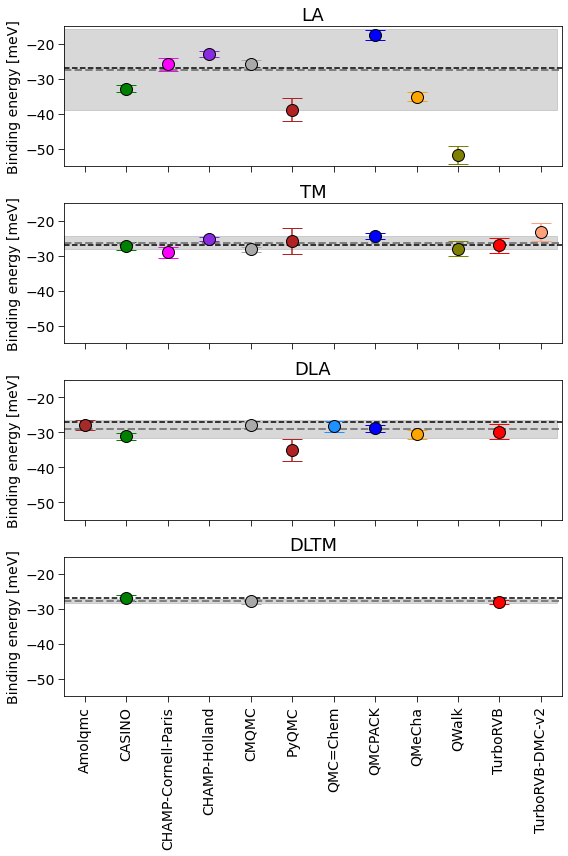

In [53]:
# figure 1 Comparison among different codes 
#fig , ax = plt.subplots(4,2,gridspec_kw={'width_ratios': [3, 1]},figsize=(10,12))
fig , ax = plt.subplots(4,1,figsize=(8,12))

# LA
ax[0].axhline(y=-27,color='black',ls='--')

#ax[0].errorbar(0,a['Amolqc']['LA'][0],a['Amolqc']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['Amolqc'])
ax[0].errorbar(1,a['CASINO']['LA'][0],a['CASINO']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CASINO'])
ax[0].errorbar(2,a['CHAMP_Cornell_Paris']['LA'][0],a['CHAMP_Cornell_Paris']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Cornell_Paris'])
ax[0].errorbar(3,a['CHAMP_Holland']['LA'][0],a['CHAMP_Holland']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Holland'])
ax[0].errorbar(4,a['CMQMC']['LA'][0],a['CMQMC']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CMQMC'])
ax[0].errorbar(5,a['PyQMC']['LA'][0],a['PyQMC']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['PyQMC'])
#ax[0].errorbar(6,a['QMC=Chem']['LA'][0],a['QMC=Chem']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMC=Chem'])
ax[0].errorbar(7,a['QMCPACK_final']['LA'][0],a['QMCPACK_final']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMCPACK_final'])
ax[0].errorbar(8,a['QMeCha']['LA'][0],a['QMeCha']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMeCha'])
ax[0].errorbar(9,a['QWalk']['LA'][0],a['QWalk']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QWalk'])
#ax[0].errorbar(10,a['TurboRVB']['LA'][0],a['TurboRVB']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB'])
#ax[0].errorbar(11,a['TurboRVB_DMCv2']['LA'][0],a['TurboRVB_DMCv2']['LA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB_DMCv2'])

ax[0].axhline(mean_codes(a,list_la,'LA')[0],c='grey',ls='dashed',lw=2)
ax[0].fill_between(np.arange(-0.5,11.5,0.1),mean_codes(a,list_la,'LA')[0] + mean_codes(a,list_la,'LA')[1],mean_codes(a,list_la,'LA')[0] - mean_codes(a,list_la,'LA')[1] ,color='grey',alpha=.3)


ax[0].set_xticks([0,1,2,3,4,5,6,7,8,9,10,11])
ax[0].set_xticklabels([])
ax[0].set_xlim([-0.5,11.5])
#ax[0].grid(ls='dotted',alpha=.7)
ax[0].tick_params(labelsize=14,size=6)
ax[0].set_title('LA',fontsize=18)

ax[0].set_ylim([-55,-15])


# TM
ax[1].axhline(y=-27,color='black',ls='--')
ax[1].errorbar(1,a['CASINO']['TM'][0],a['CASINO']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CASINO'])
ax[1].errorbar(10,a['TurboRVB']['TM'][0],a['TurboRVB']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB'])
ax[1].errorbar(11,a['TurboRVB_DMCv2']['TM'][0],a['TurboRVB_DMCv2']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB_DMCv2'])
ax[1].errorbar(7,a['QMCPACK_final']['TM'][0],a['QMCPACK_final']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMCPACK_final'])
ax[1].errorbar(4,a['CMQMC']['TM'][0],a['CMQMC']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CMQMC'])
ax[1].errorbar(3,a['CHAMP_Holland']['TM'][0],a['CHAMP_Holland']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Holland'])
ax[1].errorbar(2,a['CHAMP_Cornell_Paris']['TM'][0],a['CHAMP_Cornell_Paris']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Cornell_Paris'])
#ax[1].errorbar(6,a['QMC=Chem']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMC=Chem'])
#ax[1].errorbar(8,a['QMeCha']['TM'][0],a['QMeCha']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMeCha'])
ax[1].errorbar(5,a['PyQMC']['TM'][0],a['PyQMC']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['PyQMC'])
#ax[1].errorbar(0,a['Amolqc']['TM'][0],a['Amolqc']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['Amolqc'])
ax[1].errorbar(9,a['QWalk']['TM'][0],a['QWalk']['TM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QWalk'])

ax[1].axhline(mean_codes(a,list_tm,'TM')[0],c='grey',ls='dashed',lw=2)
ax[1].fill_between(np.arange(-0.5,11.5,0.1),mean_codes(a,list_tm,'TM')[0] + mean_codes(a,list_tm,'TM')[1],mean_codes(a,list_tm,'TM')[0] - mean_codes(a,list_tm,'TM')[1] ,color='grey',alpha=.3)



ax[1].set_xticks([0,1,2,3,4,5,6,7,8,9,10,11])
ax[1].set_xticklabels([])
ax[1].set_xlim([-0.5,11.5])
#ax[1].grid(ls='dotted',alpha=.7)
ax[1].tick_params(labelsize=14,size=6)
ax[1].set_title('TM',fontsize=18)

ax[1].set_ylim([-55,-15])


# DLA
ax[2].axhline(y=-27,color='black',ls='--')
ax[2].errorbar(1,a['CASINO']['DLA'][0],a['CASINO']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CASINO'])
ax[2].errorbar(10,a['TurboRVB']['DLA'][0],a['TurboRVB']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB'])
#ax[2].errorbar(11,a['TurboRVB_DMCv2']['DLA'][0],a['TurboRVB_DMCv2']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB_DMCv2'])
ax[2].errorbar(7,a['QMCPACK_final']['DLA'][0],a['QMCPACK_final']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMCPACK_final'])
ax[2].errorbar(4,a['CMQMC']['DLA'][0],a['CMQMC']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CMQMC'])
#ax[2].errorbar(3,a['CHAMP_Holland']['DLA'][0],a['CHAMP_Holland']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Holland'])
#ax[2].errorbar(2,a['CHAMP_Cornell_Paris']['DLA'][0],a['CHAMP_Cornell_Paris']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Cornell_Paris'])
ax[2].errorbar(6,a['QMC=Chem']['DLA'][0],a['QMC=Chem']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMC=Chem'])
ax[2].errorbar(8,a['QMeCha']['DLA'][0],a['QMeCha']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMeCha'])
ax[2].errorbar(5,a['PyQMC']['DLA'][0],a['PyQMC']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['PyQMC'])
ax[2].errorbar(0,a['Amolqc']['DLA'][0],a['Amolqc']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['Amolqc'])
#ax[2].errorbar(9,a['QWalk']['DLA'][0],a['QWalk']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QWalk'])
ax[2].axhline(mean_codes(a,list_dla,'DLA')[0],c='grey',ls='dashed',lw=2)
ax[2].fill_between(np.arange(-0.5,11.5,0.1),mean_codes(a,list_dla,'DLA')[0] - mean_codes(a,list_dla,'DLA')[1],mean_codes(a,list_dla,'DLA')[0] + mean_codes(a,list_dla,'DLA')[1] ,color='grey',alpha=.3)


ax[2].set_xticks([0,1,2,3,4,5,6,7,8,9,10,11])
ax[2].set_xticklabels([])
ax[2].set_xlim([-0.5,11.5])
#ax[2].grid(ls='dotted',alpha=.7)
ax[2].tick_params(labelsize=14,size=6)
ax[2].set_title('DLA',fontsize=18)

ax[2].set_ylim([-55,-15])


# DLTM
ax[3].axhline(y=-27,color='black',ls='--')
ax[3].errorbar(1,a['CASINO']['DLTM'][0],a['CASINO']['DLTM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CASINO'])
ax[3].errorbar(10,a['TurboRVB']['DLTM'][0],a['TurboRVB']['DLTM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB'])
#ax[3].errorbar(11,a['TurboRVB_DMCv2']['DLA'][0],a['TurboRVB_DMCv2']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['TurboRVB_DMCv2'])
#ax[3].errorbar(7,a['QMCPACK_final']['DLA'][0],a['QMCPACK_final']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMCPACK_final'])
ax[3].errorbar(4,a['CMQMC']['DLTM'][0],a['CMQMC']['DLTM'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CMQMC'])
#ax[3].errorbar(3,a['CHAMP_Holland']['DLA'][0],a['CHAMP_Holland']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Holland'])
#ax[3].errorbar(2,a['CHAMP_Cornell_Paris']['DLA'][0],a['CHAMP_Cornell_Paris']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['CHAMP_Cornell_Paris'])
#ax[3].errorbar(6,a['QMC=Chem']['DLA'][0],a['QMC=Chem']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMC=Chem'])
#ax[3].errorbar(8,a['QMeCha']['DLA'][0],a['QMeCha']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QMeCha'])
#ax[3].errorbar(5,a['PyQMC']['DLA'][0],a['PyQMC']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['PyQMC'])
#ax[3].errorbar(0,a['Amolqc']['DLA'][0],a['Amolqc']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['Amolqc'])
#ax[3].errorbar(9,a['QWalk']['DLA'][0],a['QWalk']['DLA'][1],fmt='o',capsize=10,ms=12,mec='black',c=colors['QWalk'])

ax[3].axhline(mean_codes(a,list_dltm,'DLTM')[0],c='grey',ls='dashed',lw=2)
ax[3].fill_between(np.arange(-0.5,11.5,0.1),mean_codes(a,list_dltm,'DLTM')[0] + mean_codes(a,list_dltm,'DLTM')[1],mean_codes(a,list_dltm,'DLTM')[0] - mean_codes(a,list_dltm,'DLTM')[1],color='grey',alpha=0.3)


ax[3].tick_params(labelsize=14,size=6)
ax[3].set_xticks([0,1,2,3,4,5,6,7,8,9,10,11])
ax[3].set_xlim([-0.5,11.5])
#ax[3].grid(ls='dotted',alpha=.7)
ax[3].set_title('DLTM',fontsize=18)

ax[3].set_xticklabels(['Amolqmc','CASINO','CHAMP-Cornell-Paris','CHAMP-Holland','CMQMC','PyQMC','QMC=Chem','QMCPACK','QMeCha','QWalk','TurboRVB','TurboRVB-DMC-v2'],rotation=90) 
ax[3].set_ylim([-55,-15])

ax[0].set_ylabel('Binding energy [meV]',fontsize=14)
ax[1].set_ylabel('Binding energy [meV]',fontsize=14)
ax[2].set_ylabel('Binding energy [meV]',fontsize=14)
ax[3].set_ylabel('Binding energy [meV]',fontsize=14)



plt.tight_layout()
plt.savefig('fig1.pdf',dpi=200)
plt.show()

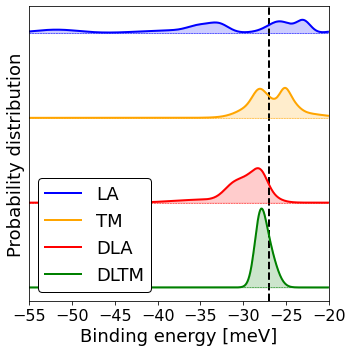

In [28]:
### figure 2 (gaussian distribution) 
x=np.arange(-55,-20,0.1)


fig , ax = plt.subplots(figsize=(5,5))

ax.axvline(-27,ls='dashed',lw=2,c='black')

ax.plot(x,gauss(x,a,list_la,'LA')+0.48*3,label='LA', lw=2,c='blue')
ax.fill_between(x,gauss(x,a,list_la,'LA')+0.48*3,0.48*3,color='blue',alpha=0.2)
ax.axhline(0.48*3,ls='dashed',lw=0.5,c='blue')



ax.plot(x,gauss(x,a,list_tm,'TM')+0.48*2,label='TM', lw=2,c='orange')
ax.fill_between(x,gauss(x,a,list_tm,'TM')+0.48*2,0.48*2,color='orange',alpha=0.2)
ax.axhline(0.48*2,ls='dashed',lw=0.5,c='orange')



ax.plot(x,gauss(x,a,list_dla,'DLA')+0.48,label='DLA', lw=2,c='red')
ax.fill_between(x,gauss(x,a,list_dla,'DLA')+0.48,0.48,color='red',alpha=0.2)
ax.axhline(0.48,ls='dashed',lw=0.5,c='red')



ax.plot(x,gauss(x,a,list_dltm,'DLTM'),label='DLTM', lw=2,c='green')
ax.fill_between(x,gauss(x,a,list_dltm,'DLTM'),0,color='green',alpha=0.2)
ax.axhline(0,ls='dashed',lw=0.5,c='green')




plt.yticks([])
plt.xticks(fontsize=16)
plt.xlim([-55,-20])
plt.ylabel('Probability distribution',fontsize=18)
plt.xlabel('Binding energy [meV]',fontsize=18)
plt.legend(fontsize=18,loc='lower left',shadow=False,framealpha=1.,facecolor='white',edgecolor='black')
plt.tight_layout()
plt.savefig('fig2.pdf',dpi=200)
plt.show()


In [38]:
# time step gaussian distribution analysis
Eb_DLA = np.load('DMC_DLA_timestep.npy',allow_pickle=True).item()

In [39]:
Eb_DLA['CASINO'].loc[0.0025]['ene']
list_tau=['CASINO','Amolqc','CMQMC','PyQMC','QMC=Chem','QMCPACK_final']

def gauss_tau (x, a, lista, tau):
    
    # a is the dictionary
    # lista is the list of codes to consider
    # method is the algorithm, eg 'LA'
    import scipy.stats as stats
    gauss = 0
    for i in lista:
        gauss += stats.norm.pdf(x, a[i].loc[tau][0], a[i].loc[tau][1])
    gauss /= len(lista)
    return gauss

In [40]:
# here we call gauss_tau

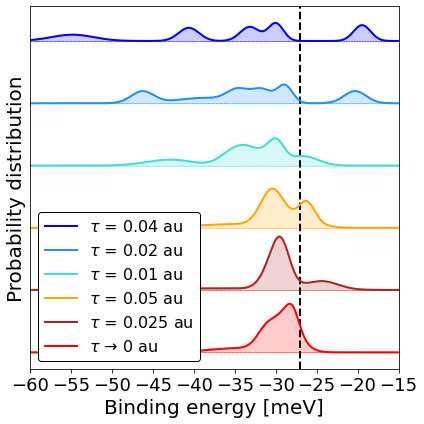

In [41]:
x=np.arange(-60,-10,0.1)
offset=0.25

fig , ax = plt.subplots(figsize=(6,6))

ax.axvline(-27,ls='dashed',lw=2,c='black')

ax.plot(x,gauss_tau(x,Eb_DLA,list_tau,0.0400)+offset*5,label=r'$\tau$ = 0.04 au',lw=2,c='blue')
ax.fill_between(x,gauss_tau(x,Eb_DLA,list_tau,0.0400)+offset*5,offset*5,color='blue',alpha=0.2)
ax.axhline(offset*5,ls='dashed',lw=0.5,c='blue')


ax.plot(x,gauss_tau(x,Eb_DLA,list_tau,0.0200)+offset*4,label=r'$\tau$ = 0.02 au',lw=2,c='dodgerblue')
ax.fill_between(x,gauss_tau(x,Eb_DLA,list_tau,0.0200)+offset*4,offset*4,color='dodgerblue',alpha=0.2)
ax.axhline(offset*4,ls='dashed',lw=0.5,c='dodgerblue')

ax.plot(x,gauss_tau(x,Eb_DLA,list_tau,0.0100)+offset*3,label=r'$\tau$ = 0.01 au',lw=2,c='turquoise')
ax.fill_between(x,gauss_tau(x,Eb_DLA,list_tau,0.0100)+offset*3,offset*3,color='turquoise',alpha=0.2)
ax.axhline(offset*3,ls='dashed',lw=0.5,c='turquoise')

ax.plot(x,gauss_tau(x,Eb_DLA,list_tau,0.0050)+offset*2,label=r'$\tau$ = 0.05 au',lw=2,c='orange')
ax.fill_between(x,gauss_tau(x,Eb_DLA,list_tau,0.005)+offset*2,offset*2,color='orange',alpha=0.2)
ax.axhline(offset*2,ls='dashed',lw=0.5,c='orange')

ax.plot(x,gauss_tau(x,Eb_DLA,list_tau,0.0025)+offset,label=r'$\tau$ = 0.025 au', lw=2,c='firebrick')
ax.fill_between(x,gauss_tau(x,Eb_DLA,list_tau,0.0025)+offset,offset,color='firebrick',alpha=0.2)
ax.axhline(offset,ls='dashed',lw=0.5,c='firebrick')

ax.plot(x,gauss(x,a,list_dla,'DLA'),label=r'$\tau$ $\to$ 0 au', lw=2,c='red')
ax.fill_between(x,gauss(x,a,list_dla,'DLA'),0,color='red',alpha=0.2)
ax.axhline(0,ls='dashed',lw=0.5,c='red')



plt.yticks([])
plt.xlim([-60,-15])
plt.xticks(fontsize=18)
plt.ylabel('Probability distribution',fontsize=20)
plt.xlabel('Binding energy [meV]',fontsize=20)
plt.legend(fontsize=16,loc='lower left',shadow=False,framealpha=1.,facecolor='white',edgecolor='black')

plt.tight_layout()
plt.savefig('fig3.pdf',dpi=200)


plt.show()